# Visual Model — Predictions on Primary Experiment Clips

Runs the calibrated 4-layer Roseboom-equation visual accumulator on the 36 primary experiment videos.

## Pipeline
1. Load model artifact + pickled SVR pipeline from `models/`
2. For each clip folder in `data/processed/frames/<clip_id>/`:
   - Load JPEG frames at 30 fps
   - Extract per-layer L2 distances (conv2, pool5, fc7, output)
   - Run accumulator with paper's Equation (1)
   - Build feature vector (raw + log1p ticks per layer)
   - Predict via pickled SVR pipeline
3. Save `clip_predictions.csv` with per-clip predictions

In [1]:
# ============================================================================
# SECTION 1: Imports
# ============================================================================

import json
import pickle
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
from typing import Optional, Dict
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torchvision.transforms as T
from torchvision.models import alexnet, AlexNet_Weights

import matplotlib.pyplot as plt
from scipy.stats import pearsonr

print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

PyTorch: 2.4.1+cu121
CUDA available: True


In [2]:
# ============================================================================
# SECTION 2: Load Calibrated Model and SVR Pipeline
# ============================================================================

PROJECT_ROOT = Path.cwd().parent
MODELS_DIR   = PROJECT_ROOT / "models"
FRAMES_DIR   = PROJECT_ROOT / "data" / "processed" / "frames"
OUT_DIR      = PROJECT_ROOT / "results" / "visual" / "travel"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Load JSON artifact (parameters)
model_path = MODELS_DIR / "visual_accumulator_latest.json"
assert model_path.exists(), f"Run visual_model.ipynb first to create {model_path}"
with open(model_path) as f:
    saved_model = json.load(f)

ATTENTION_C  = saved_model["params"]["ATTENTION_C"]
LAYER_PARAMS = saved_model["params"]["layer_params"]

# Choose which calibration to use:
#   "physical" → SVR trained on real_duration (paper-faithful, primary scientific result)
#   "human"    → SVR trained on human_estimates (better-aligned with human ratings, used for late fusion)
CALIBRATION = "human"   # change to "physical" to use the primary model

svr_pickle_path = MODELS_DIR / f"visual_svr_{CALIBRATION}.pkl"
assert svr_pickle_path.exists(), (
    f"Run visual_model.ipynb first to create {svr_pickle_path}. "
    f"Make sure both visual_svr_physical.pkl and visual_svr_human.pkl exist."
)
with open(svr_pickle_path, "rb") as f:
    svr_pipeline = pickle.load(f)

print(f"Calibration mode: {CALIBRATION}")
print(f"Loaded SVR:       {svr_pickle_path.name}")

# Constants
LAYERS     = ["conv2", "pool5", "fc7", "output"]
SAMPLE_FPS = 30
BATCH_SIZE = 64
device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Model:           {saved_model['name']}")
print(f"Created:         {saved_model['created_at']}")
print(f"ATTENTION_C:     {ATTENTION_C}")
print(f"Validation r:    {saved_model['metrics']['pearson_r_vs_human']:.3f}")
print(f"Validation MAE:  {saved_model['metrics']['mae_vs_human']:.2f}s")
print(f"Device:          {device}")

Calibration mode: human
Loaded SVR:       visual_svr_human.pkl
Model:           visual_accumulator_4layer
Created:         2026-05-01T12:23:46
ATTENTION_C:     0.67
Validation r:    0.688
Validation MAE:  7.41s
Device:          cuda


In [3]:
# ============================================================================
# SECTION 3: Build 4-Layer AlexNet Feature Extractor
# (matches visual_model.ipynb Section 3 exactly)
# ============================================================================

def build_model(device: torch.device) -> dict:
    weights = AlexNet_Weights.DEFAULT
    base = alexnet(weights=weights).to(device)
    base.eval()

    extractors = {
        'conv2':  nn.Sequential(*list(base.features.children())[:6]).to(device),
        'pool5':  nn.Sequential(*list(base.features.children())).to(device),
        'fc7':    nn.Sequential(base.features, base.avgpool, nn.Flatten(),
                                nn.Sequential(*list(base.classifier.children())[:6])).to(device),
        'output': nn.Sequential(base.features, base.avgpool, nn.Flatten(),
                                base.classifier,
                                nn.Softmax(dim=1)).to(device),
    }
    for ext in extractors.values():
        ext.eval()
    return extractors

def build_transform():
    return T.Compose([
        T.Resize((224, 224)),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406],
                    std=[0.229, 0.224, 0.225]),
    ])

extractors = build_model(device)
transform  = build_transform()
print(f"Extractors ready: {list(extractors.keys())}")

Extractors ready: ['conv2', 'pool5', 'fc7', 'output']


In [4]:
# ============================================================================
# SECTION 4: Roseboom Equation (1) Accumulator
# (matches visual_model.ipynb Section 5 exactly)
# ============================================================================

def accumulate_ticks(dist: np.ndarray, T_max: float, T_min: float,
                     tau: float, alpha: float, attention_C: float,
                     rng: Optional[np.random.Generator] = None) -> int:
    if rng is None:
        rng = np.random.default_rng()

    Tmax_c = attention_C * T_max
    Tmin_c = attention_C * T_min

    ticks = 0
    D = 0
    T = Tmax_c

    for xi in dist:
        decay = ((Tmax_c - Tmin_c) / tau) * np.exp(-D / tau)
        noise = rng.normal(0.0, (Tmax_c - Tmin_c) / alpha)
        T = T - decay + noise

        if xi > T:
            ticks += 1
            T = Tmax_c
            D = 0
        else:
            D += 1

    return int(ticks)

print("Accumulator ready")

Accumulator ready


In [5]:
# ============================================================================
# SECTION 5: Run Pipeline on All Clip Folders
# ============================================================================

def extract_layer_l2s(frame_paths, extractors, transform, device, batch_size=64):
    """Returns dict {layer_name: l2_distances_array} for a list of frame paths."""
    layer_embs = {k: [] for k in extractors}
    with torch.no_grad():
        for i in range(0, len(frame_paths), batch_size):
            batch_paths = frame_paths[i:i + batch_size]
            imgs = [transform(Image.open(p).convert("RGB")) for p in batch_paths]
            batch = torch.stack(imgs, 0).to(device)
            for k, ext in extractors.items():
                emb = ext(batch).detach().cpu().numpy()
                layer_embs[k].append(emb)
    
    layer_l2s = {}
    for k, embs_list in layer_embs.items():
        embs = np.concatenate(embs_list, axis=0)
        if embs.ndim > 2:
            embs = embs.reshape(embs.shape[0], -1)
        n = embs.shape[0]
        l2 = np.zeros(n, dtype=np.float32)
        if n > 1:
            l2[1:] = np.linalg.norm(np.diff(embs, axis=0), axis=1)
        layer_l2s[k] = l2
    return layer_l2s


clip_folders = sorted(
    [d for d in FRAMES_DIR.iterdir() if d.is_dir() and any(d.glob("frame_*.jpg"))],
    key=lambda d: int(d.name) if d.name.isdigit() else 0
)
print(f"Found {len(clip_folders)} clip folder(s) in {FRAMES_DIR}")
print("=" * 70)

rng = np.random.default_rng(seed=42)
results = []

for clip_folder in tqdm(clip_folders, desc="Clips"):
    clip_id = clip_folder.name
    frame_paths = sorted(clip_folder.glob("frame_*.jpg"))
    if len(frame_paths) == 0:
        continue

    times_path = clip_folder / "frame_times.npy"
    if times_path.exists():
        times = np.load(str(times_path))
        n = min(len(frame_paths), len(times))
        frame_paths = frame_paths[:n]
        times = times[:n]
    else:
        times = np.arange(len(frame_paths), dtype=np.float32) / SAMPLE_FPS

    duration_s = float(times[-1]) if len(times) > 0 else 0.0

    # Extract per-layer L2 distances
    layer_l2s = extract_layer_l2s(frame_paths, extractors, transform, device,
                                    batch_size=BATCH_SIZE)

    # Run accumulator per layer
    ticks_per_layer = {}
    for layer in LAYERS:
        p = LAYER_PARAMS[layer]
        ticks_per_layer[layer] = accumulate_ticks(
            layer_l2s[layer],
            T_max=p['T_max'], T_min=p['T_min'],
            tau=p['tau'], alpha=p['alpha'],
            attention_C=ATTENTION_C, rng=rng,
        )

    # Build feature vector matching SVR training: [raw_ticks_4, log1p_ticks_4]
    raw  = np.array([ticks_per_layer[l] for l in LAYERS], dtype=np.float32)
    feat = np.log1p(raw).reshape(1, -1)

    # Predict via pickled SVR pipeline
    pred_s = float(svr_pipeline.predict(feat)[0])

    results.append({
        "clip_id":          clip_id,
        "n_frames":         len(frame_paths),
        "duration_s":       duration_s,
        "ticks_conv2":      ticks_per_layer['conv2'],
        "ticks_pool5":      ticks_per_layer['pool5'],
        "ticks_fc7":        ticks_per_layer['fc7'],
        "ticks_output":     ticks_per_layer['output'],
        "pred_perceived_s": pred_s,
    })

results_df = pd.DataFrame(results)
print(f"\nProcessed {len(results_df)} clips")

Found 36 clip folder(s) in D:\Sahil\Capstone_Project\data\processed\frames


Clips: 100%|███████████████████████████████████████████████████████████████████████████| 36/36 [03:46<00:00,  6.28s/it]


Processed 36 clips


In [6]:
# ============================================================================
# SECTION 6: Save Predictions
# ============================================================================

out_csv = OUT_DIR / f"travel_clip_predictions_{CALIBRATION}.csv"
results_df.to_csv(out_csv, index=False)
print(f"Predictions saved: {out_csv}")

meta = {
    "model":      saved_model["name"],
    "created_at": saved_model["created_at"],
    "run_at":     datetime.now().isoformat(timespec="seconds"),
    "n_clips":    len(results_df),
    "params":     saved_model["params"],
    "calibration": saved_model["calibration"],
    "summary": {
        "mean_predicted_s": float(round(results_df['pred_perceived_s'].mean(), 2)),
        "mean_actual_s":    float(round(results_df['duration_s'].mean(), 2)),
    },
}
with open(OUT_DIR / f"travel_predictions_meta_{CALIBRATION}.json", "w") as f:
    json.dump(meta, f, indent=2)

print("\nResults preview:")
print(results_df.to_string(index=False))

Predictions saved: D:\Sahil\Capstone_Project\results\visual\travel\travel_clip_predictions_human.csv

Results preview:
clip_id  n_frames  duration_s  ticks_conv2  ticks_pool5  ticks_fc7  ticks_output  pred_perceived_s
      1       739   24.600000          471            2         61            11         22.829178
      2       720   23.966667          629            3        109            12         27.811617
      3       724   24.100000          167            2         33            10         17.882811
      4       798   26.566668          583            4        124            12         29.239087
      5       716   23.833334           26            2         10             3         12.529307
      6       738   24.566668          166            2         43             7         15.460241
      7       841   28.000000          566            1        604           237         28.418460
      8       792   26.366667          328            4         82            11         

VISUAL MODEL vs HUMAN VIDEO-ONLY ESTIMATES
  Clips matched: 36
  Pearson r:     0.497
  MAE:           5.69s
  RMSE:          6.66s
  Mean bias:     -0.65s (underestimates)


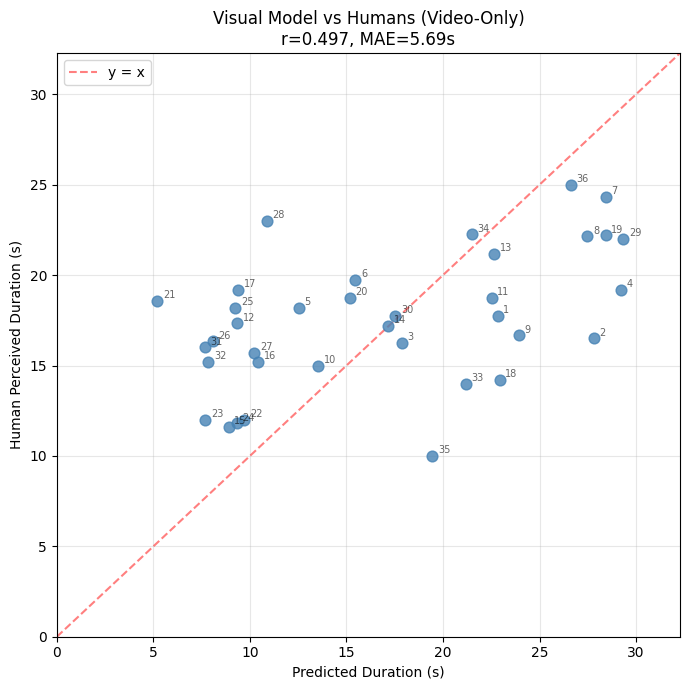

In [7]:
# ============================================================================
# SECTION 7: Compare Against Human Video-Only Estimates
# ============================================================================

VIDEO_LABELS_PATH = PROJECT_ROOT / "data" / "labels" / "video_perceived.csv"

if not VIDEO_LABELS_PATH.exists():
    print(f"Labels file not found: {VIDEO_LABELS_PATH}")
else:
    labels_df = pd.read_csv(VIDEO_LABELS_PATH)
    labels_df["clip_id"]      = labels_df["clip_id"].astype(str).str.strip()
    results_df["clip_id_str"] = results_df["clip_id"].astype(str).str.strip()

    merged = results_df.merge(labels_df[["clip_id", "perceived_s"]],
                              left_on="clip_id_str", right_on="clip_id", how="inner")

    if len(merged) == 0:
        print("No matching clips between predictions and human labels.")
    else:
        r    = pearsonr(merged["pred_perceived_s"], merged["perceived_s"])[0]
        mae  = float(np.abs(merged["pred_perceived_s"] - merged["perceived_s"]).mean())
        bias = float((merged["pred_perceived_s"] - merged["perceived_s"]).mean())
        rmse = float(np.sqrt(((merged["pred_perceived_s"] - merged["perceived_s"]) ** 2).mean()))

        print("=" * 60)
        print("VISUAL MODEL vs HUMAN VIDEO-ONLY ESTIMATES")
        print("=" * 60)
        print(f"  Clips matched: {len(merged)}")
        print(f"  Pearson r:     {r:.3f}")
        print(f"  MAE:           {mae:.2f}s")
        print(f"  RMSE:          {rmse:.2f}s")
        print(f"  Mean bias:     {bias:+.2f}s ({'over' if bias > 0 else 'under'}estimates)")

        fig, ax = plt.subplots(figsize=(7, 7))
        ax.scatter(merged["pred_perceived_s"], merged["perceived_s"],
                   color="steelblue", alpha=0.8, s=60, zorder=3)
        for _, row in merged.iterrows():
            ax.annotate(str(row["clip_id_str"]),
                        (row["pred_perceived_s"], row["perceived_s"]),
                        fontsize=7, alpha=0.6, textcoords="offset points", xytext=(4, 2))
        all_vals = pd.concat([merged["pred_perceived_s"], merged["perceived_s"]])
        axis_max = all_vals.max() * 1.1
        ax.plot([0, axis_max], [0, axis_max], "r--", alpha=0.5, label="y = x")
        ax.set_xlim(0, axis_max); ax.set_ylim(0, axis_max)
        ax.set_xlabel("Predicted Duration (s)")
        ax.set_ylabel("Human Perceived Duration (s)")
        ax.set_title(f"Visual Model vs Humans (Video-Only)\nr={r:.3f}, MAE={mae:.2f}s")
        ax.legend(); ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.savefig(OUT_DIR / "travel_visual_vs_human.png", dpi=150, bbox_inches="tight")
        plt.show()